# Phase 2 – Exploratory Data Analysis (10 charts)
**Analyst: Vaishali Girase**

In [1]:
import pandas as pd, numpy as np, glob, os
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

# 1) Put this notebook in the SAME folder as the CSV files (or change DATA_DIR)
DATA_DIR = "/kaggle/input/datasets/vaishaligirase/indiakart"

def load(name):
    """Finds e.g. 'orders DA.csv' or 'orders.csv' automatically."""
    hits = glob.glob(os.path.join(DATA_DIR, name + "*.csv"))
    return pd.read_csv(hits[0])

orders, items, customers = load("orders"), load("order_items"), load("customers")
products, payments = load("products"), load("payments")
returns, inventory, suppliers = load("returns"), load("inventory"), load("suppliers")

# 2) Convert dates (Indian format DD-MM-YYYY)
orders["order_date"] = pd.to_datetime(orders["order_date"], format="%d-%m-%Y")
orders["delivered_date"] = pd.to_datetime(orders["delivered_date"], format="%d-%m-%Y")
customers["registration_date"] = pd.to_datetime(customers["registration_date"], format="%d-%m-%Y")
returns["return_date"] = pd.to_datetime(returns["return_date"], format="%d-%m-%Y")

os.makedirs("charts", exist_ok=True)
orders["month"] = orders["order_date"].dt.to_period("M")
def save(name): plt.tight_layout(); plt.savefig(f"charts/{name}.png", dpi=130); plt.show()

## Chart 1 – Monthly order volume (Oct/Nov highlighted)

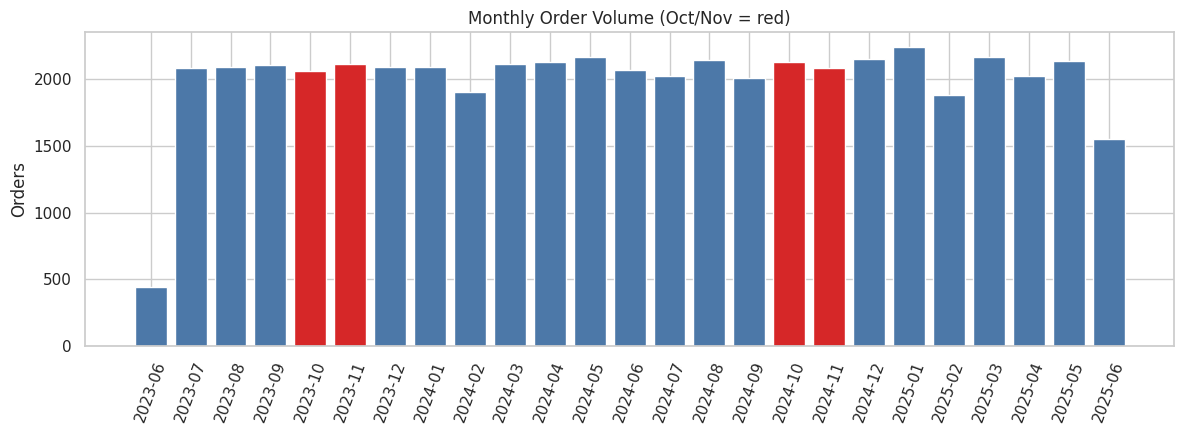

Oct+Nov share of all orders: 16.8% (an even 2/12 would be 16.7%)


In [2]:
mo = orders.groupby("month").size()
labels = [str(x) for x in mo.index]
colors = ["#d62728" if l[-2:] in ("10","11") else "#4c78a8" for l in labels]
plt.figure(figsize=(12,4.5)); plt.bar(labels, mo.values, color=colors)
plt.xticks(rotation=70); plt.title("Monthly Order Volume (Oct/Nov = red)"); plt.ylabel("Orders"); save("01_monthly_orders")
print("Oct+Nov share of all orders: %.1f%% (an even 2/12 would be 16.7%%)" % (orders["order_date"].dt.month.isin([10,11]).mean()*100))

**Observation:** Orders grew from ~2,000/month (Jul 2023) to a peak of 2,239 in Jan 2025. June 2023 and June 2025 are partial months (data starts 24-Jun-23 and ends 23-Jun-25). Oct–Nov hold 16.8% of orders – almost exactly an even share – so **there is no visible Diwali spike** in this dataset.

## Chart 2 – Monthly revenue (GMV) with year-over-year comparison

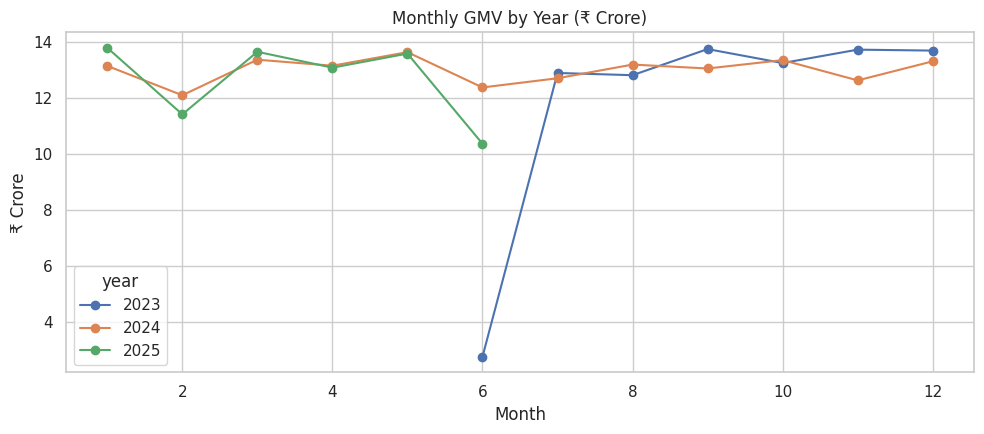

Year 1 GMV ₹157.7 Cr | Year 2 GMV ₹157.1 Cr | change -0.4%


In [3]:
orders["year"]=orders["order_date"].dt.year; orders["mon"]=orders["order_date"].dt.month
pv = orders.pivot_table(index="mon", columns="year", values="final_amount", aggfunc="sum")/1e7
pv.plot(marker="o", figsize=(10,4.5)); plt.title("Monthly GMV by Year (₹ Crore)"); plt.ylabel("₹ Crore"); plt.xlabel("Month"); save("02_monthly_gmv_yoy")
yr1 = orders[orders.order_date<"2024-06-24"]["final_amount"].sum(); yr2 = orders[orders.order_date>="2024-06-24"]["final_amount"].sum()
print("Year 1 GMV ₹%.1f Cr | Year 2 GMV ₹%.1f Cr | change %.1f%%" % (yr1/1e7, yr2/1e7, (yr2/yr1-1)*100))

**Observation:** Year 2 GMV is essentially flat vs Year 1 (≈ −0.4%). Growth happened early (2023-24) and has plateaued – management should look at acquisition/retention.

## Chart 3 – Category revenue share

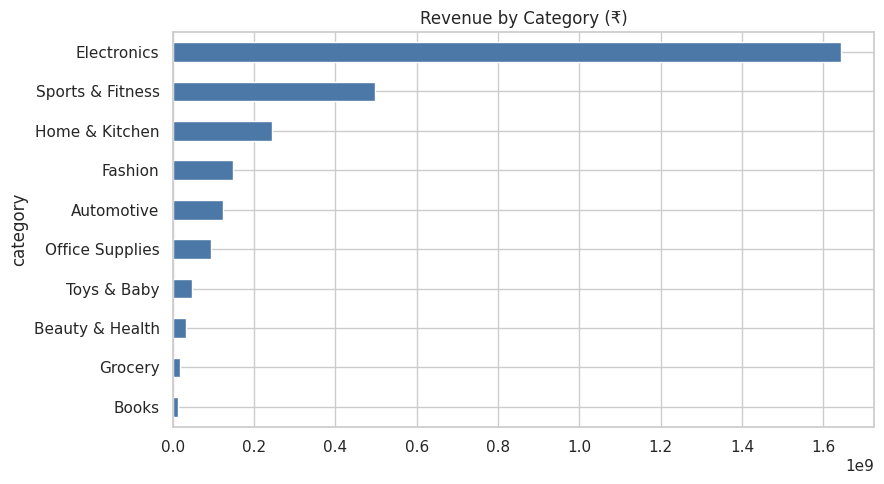

category
Electronics        57.40
Sports & Fitness   17.40
Home & Kitchen      8.50
Fashion             5.20
Automotive          4.30
Office Supplies     3.30
Toys & Baby         1.60
Beauty & Health     1.20
Grocery             0.70
Books               0.50
Name: total_price, dtype: float64


In [4]:
cat = items.groupby("category")["total_price"].sum().sort_values()
cat.plot.barh(figsize=(9,5), color="#4c78a8"); plt.title("Revenue by Category (₹)"); save("03_category_revenue")
print((cat/cat.sum()*100).round(1).sort_values(ascending=False))

**Observation:** Electronics alone earns **57.4%** of revenue, followed by Sports & Fitness (17.4%). Grocery, Books and Beauty & Health together are under 3% – high concentration risk.

## Chart 4 – Order status distribution (donut)

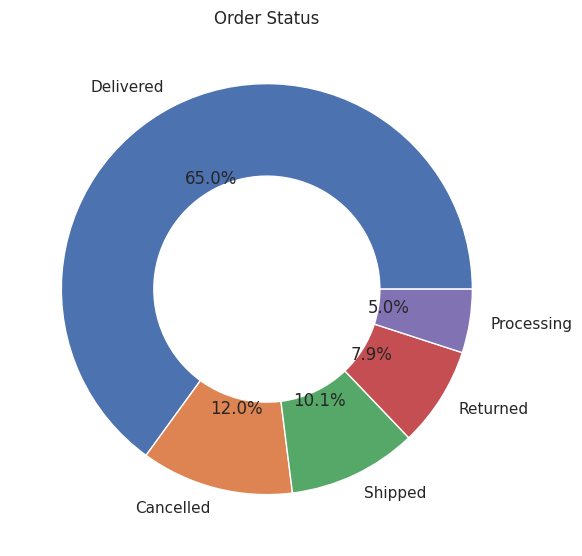

In [5]:
st = orders["status"].value_counts()
plt.figure(figsize=(6,6)); plt.pie(st, labels=st.index, autopct="%1.1f%%", wedgeprops=dict(width=.45)); plt.title("Order Status"); save("04_order_status")

**Observation:** 65% delivered, 12% cancelled (above the 10% target) and 7.9% marked Returned.

## Chart 5 – Top 10 states by orders

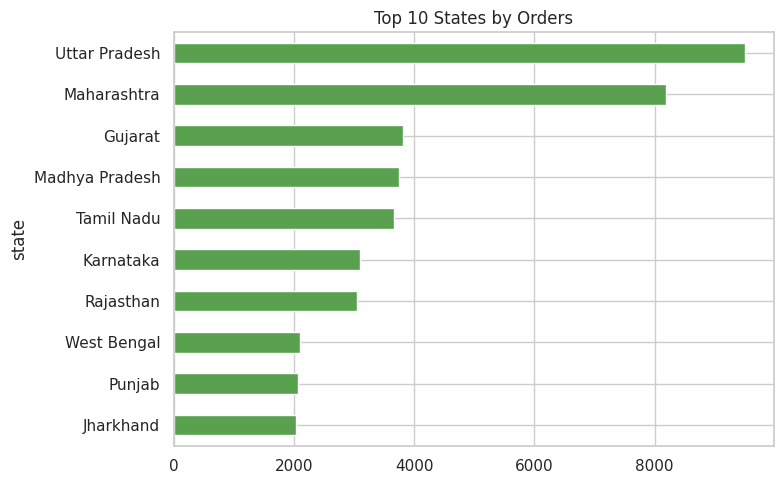

In [6]:
s = orders["state"].value_counts().head(10)
s[::-1].plot.barh(figsize=(8,5), color="#59a14f"); plt.title("Top 10 States by Orders"); save("05_top_states")

**Observation:** Uttar Pradesh (9,507) and Maharashtra (8,179) lead; together they are ~35% of orders. Gujarat is #3.

## Chart 6 – Customer segment distribution

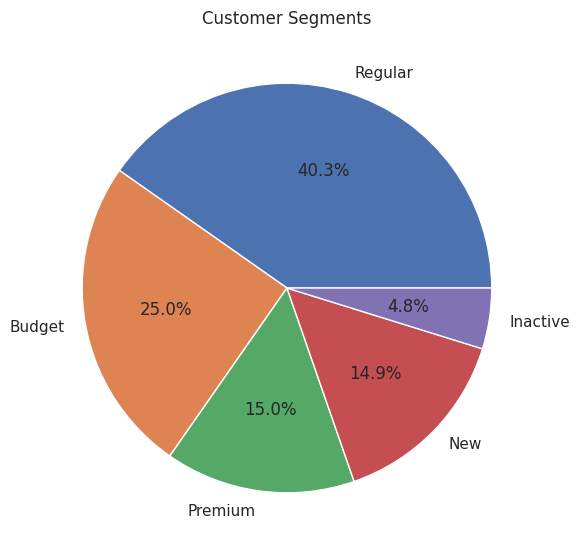

In [7]:
sg = customers["segment"].value_counts()
plt.figure(figsize=(6,6)); plt.pie(sg, labels=sg.index, autopct="%1.1f%%"); plt.title("Customer Segments"); save("06_segments")

**Observation:** Regular (40%) is the biggest group; Premium is 15% (1,501 customers); Inactive is under 5%.

## Chart 7 – Payment method usage

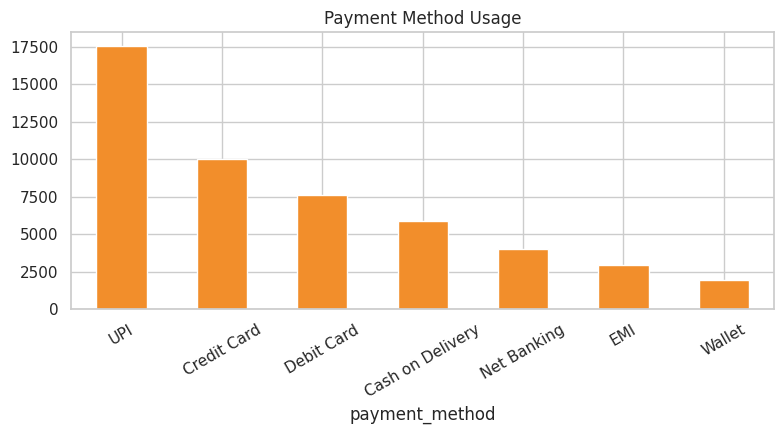

In [8]:
pm = orders["payment_method"].value_counts()
pm.plot.bar(figsize=(8,4.5), color="#f28e2b"); plt.xticks(rotation=30); plt.title("Payment Method Usage"); save("07_payment_methods")

**Observation:** UPI is #1 (35%), then Credit Card (20%) and Debit Card (15%). COD is ~12%.

## Chart 8 – Age distribution

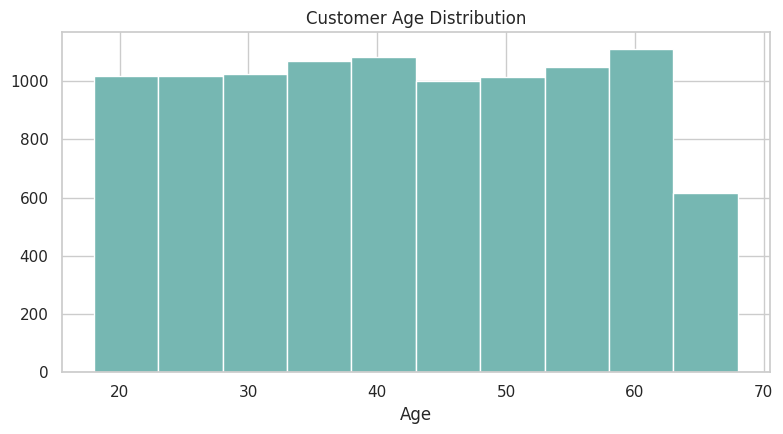

In [9]:
plt.figure(figsize=(8,4.5)); plt.hist(customers["age"], bins=range(18,70,5), color="#76b7b2", edgecolor="white")
plt.title("Customer Age Distribution"); plt.xlabel("Age"); save("08_age")

**Observation:** Ages are spread fairly evenly from 18–65; the 55–65 and 35–44 groups are slightly the largest. Shoppers are not only "young" – marketing should not target only under-30s.

## Chart 9 – Return reasons

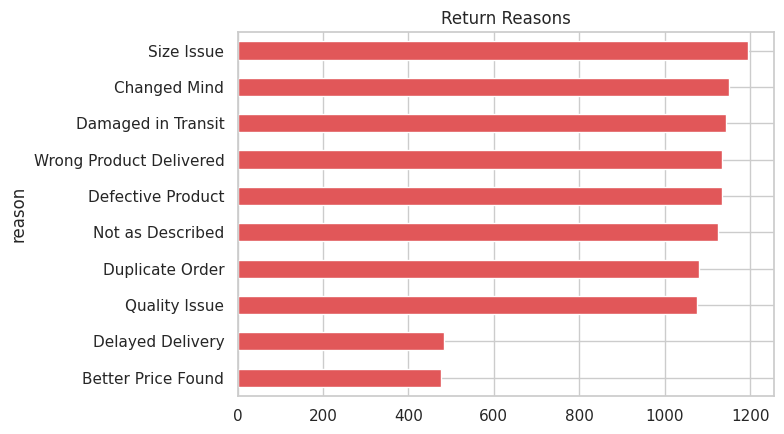

In [10]:
rr = returns["reason"].value_counts()
rr[::-1].plot.barh(figsize=(8,4.5), color="#e15759"); plt.title("Return Reasons"); save("09_return_reasons")

**Observation:** Eight reasons are almost equal (~1,100 each). Reasons that the company controls – *Damaged in Transit, Wrong Product Delivered, Defective, Not as Described, Quality Issue* – make up about 56% of all returns.

## Chart 10 – Average Order Value by segment

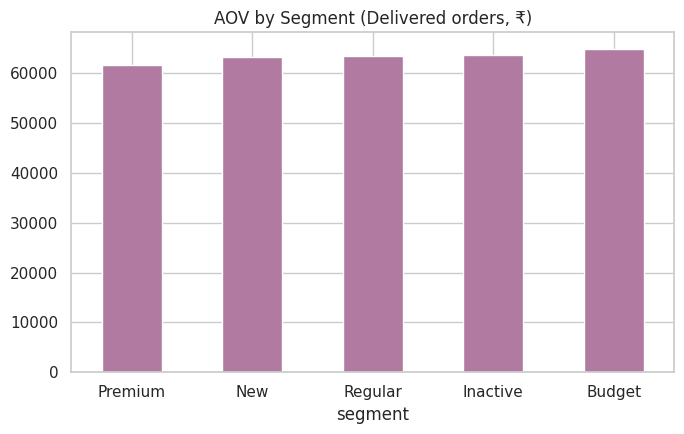

segment
Premium    61,691.60
New        63,277.66
Regular    63,458.41
Inactive   63,638.69
Budget     64,951.14
Name: final_amount, dtype: float64

In [11]:
oc = orders.merge(customers[["customer_id","segment"]], on="customer_id")
aov = oc[oc.status=="Delivered"].groupby("segment")["final_amount"].mean().sort_values()
aov.plot.bar(figsize=(7,4.5), color="#b07aa1"); plt.xticks(rotation=0); plt.title("AOV by Segment (Delivered orders, ₹)"); save("10_aov_segment")
aov

**Observation:** AOV is almost the same (~₹62–65k) in every segment. Premium customers are valuable because they place **more orders** (8.6 per customer vs 5.7 for Regular), not because each order is bigger.